In [2]:
# 회귀분석

# 그래프관련 import
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False
# 프로그램 관련 import
import pandas as pd
from sklearn import svm,metrics
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor # 예측관련(regression)
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error # 평균절대오차 오차범위
from sklearn.neighbors import KNeighborsClassifier # 분류 관련(classifier)
from sklearn.preprocessing import StandardScaler # 정규화클래스
import numpy as np

In [3]:
perch_length = np.array(
    [8.4, 13.7, 15.0, 16.2, 17.4, 18.0, 18.7, 19.0, 19.6, 20.0,
    21.0, 21.0, 21.0, 21.3, 22.0, 22.0, 22.0, 22.0, 22.0, 22.5,
    22.5, 22.7, 23.0, 23.5, 24.0, 24.0, 24.6, 25.0, 25.6, 26.5,
    27.3, 27.5, 27.5, 27.5, 28.0, 28.7, 30.0, 32.8, 34.5, 35.0,
    36.5, 36.0, 37.0, 37.0, 39.0, 39.0, 39.0, 40.0, 40.0, 40.0,
    40.0, 42.0, 43.0, 43.0, 43.5, 44.0]
    )
perch_weight = np.array(
    [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0,
    110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
    130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0,
    197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
    514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0,
    820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0,
    1000.0, 1000.0]
    )

In [4]:
# 학습데이터, 테스트데이터 분리
train_data, test_data, train_label, test_label = train_test_split(perch_length,perch_weight)

In [5]:
train_data = train_data.reshape(-1,1)
test_data = test_data.reshape(-1,1)
test_data[:3] # 자료 형태 확인

array([[30. ],
       [28.7],
       [36.5]])

In [6]:
# 데이터 학습
lr = LinearRegression()
lr.fit(train_data, train_label)

# 데이터 예측
predict = lr.predict(test_data)
print("무게예측:", predict)

# 정확도
score = lr.score(train_data,train_label)
score2 = lr.score(test_data,test_label)
print("train정확도", score)
print("test정확도", score2)
# train정확도가 test정확도보다 높을 때 적합함. 5~10% 정도

# 기울기, 절편 : LinearRegression 일 때만 나타남
print('기울기 :', lr.coef_)
print('절편 :', lr.intercept_)

무게예측: [ 4.71819315e+02  4.23212417e+02  7.14853804e+02  9.76583254e+02
  1.91394904e+02  1.35310022e+02  8.45718529e+02  2.84869708e+02
  3.70866527e+02  5.76511095e+02 -8.90295061e+01  7.06305236e-01
  3.40954590e+02  1.72699944e+02]
train정확도 0.918974681250702
test정확도 0.9109299070069297
기울기 : [37.3899214]
절편 : -649.8783271198479


In [7]:
# KNeighborsRegressior 50-1000
# 50cm 농어 예측
predict2 = lr.predict([[50]])
print("몸무게",predict2)

몸무게 [1219.61774287]


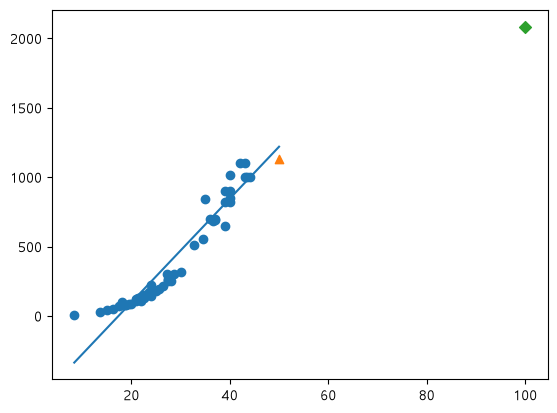

In [8]:
# 산점도 그래프
plt.scatter(perch_length, perch_weight)
plt.scatter(50, 1132, marker='^')
plt.scatter(100, 2085, marker='D')
plt.plot([8.4,50],[8.4*lr.coef_+lr.intercept_, 50*lr.coef_+lr.intercept_])
plt.show()


In [9]:
# 길이를 입력받아, 무게를 예측하고, 산점도 그래프에 표시하시오.
# 농어길이를 입력하세요. 예)52
# 예측무게
# 산점도 그래프에 표시
# 선그래프도 함께 표시

In [10]:
length1 = input("길이를 입력하세요:")
length1 = float(length1)
predict3 = lr.predict([[length1]])
print("예측무게:", predict3)

ValueError: could not convert string to float: ''

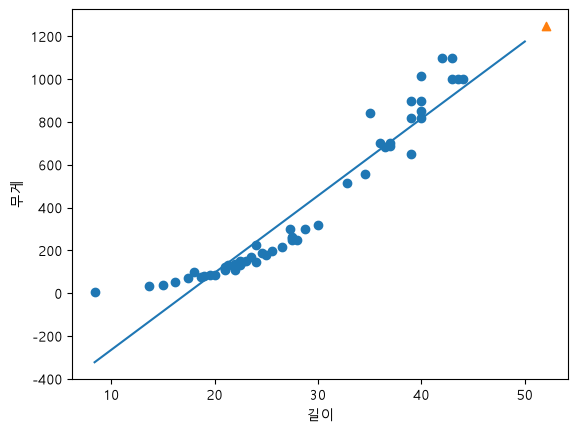

기울기 [36.00737935]
절편 -624.6031430579417


In [28]:
plt.scatter(perch_length, perch_weight)
plt.scatter(52,1247,marker='^')
plt.plot([8.4,50],[8.4*lr.coef_+lr.intercept_,50*lr.coef_+lr.intercept_])  # 선그래프
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()
print('기울기', lr.coef_)
print('절편', lr.intercept_)